In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [ ]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
        'Insulin', 'BMI', 'DiabetesPedigree', 'Age', 'Outcome']
df = pd.read_csv(url, header=None, names=cols)
print("Shape:", df.shape)

Shape: (768, 9)


In [ ]:
df = df.drop_duplicates()

# 3b. Handle missing values.
# In this dataset, missing values are hidden as 0s. A Glucose or BMI
# of 0 is medically impossible, so we treat those 0s as missing (NaN)...
invalid_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[invalid_zero] = df[invalid_zero].replace(0, np.nan)

# ...then fill them with the column median (robust to outliers).
df = df.fillna(df.median())

In [ ]:
X = df.drop('Outcome', axis=1)          # features
y = df['Outcome']                       # target: 0 = no diabetes, 1 = diabetes

# 80% train / 20% test. stratify keeps the same class ratio in both splits.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# max_depth + min_samples_leaf stop the tree from memorising the data
model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=42)
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=42)

In [ ]:
y_pred = model.predict(X_test)

print("\nTest accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Train accuracy:", round(accuracy_score(y_train, model.predict(X_train)), 3))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\n", classification_report(y_test, y_pred,
                                   target_names=['No diabetes', 'Diabetes']))


Test accuracy : 0.792
Train accuracy: 0.785

Confusion matrix:
 [[83 17]
 [15 39]]

               precision    recall  f1-score   support

 No diabetes       0.85      0.83      0.84       100
    Diabetes       0.70      0.72      0.71        54

    accuracy                           0.79       154
   macro avg       0.77      0.78      0.77       154
weighted avg       0.79      0.79      0.79       154



Feature importance:
 Glucose             0.699
BMI                 0.149
Age                 0.137
Pregnancies         0.015
SkinThickness       0.000
BloodPressure       0.000
Insulin             0.000
DiabetesPedigree    0.000
dtype: float64

Saved decision_tree.png


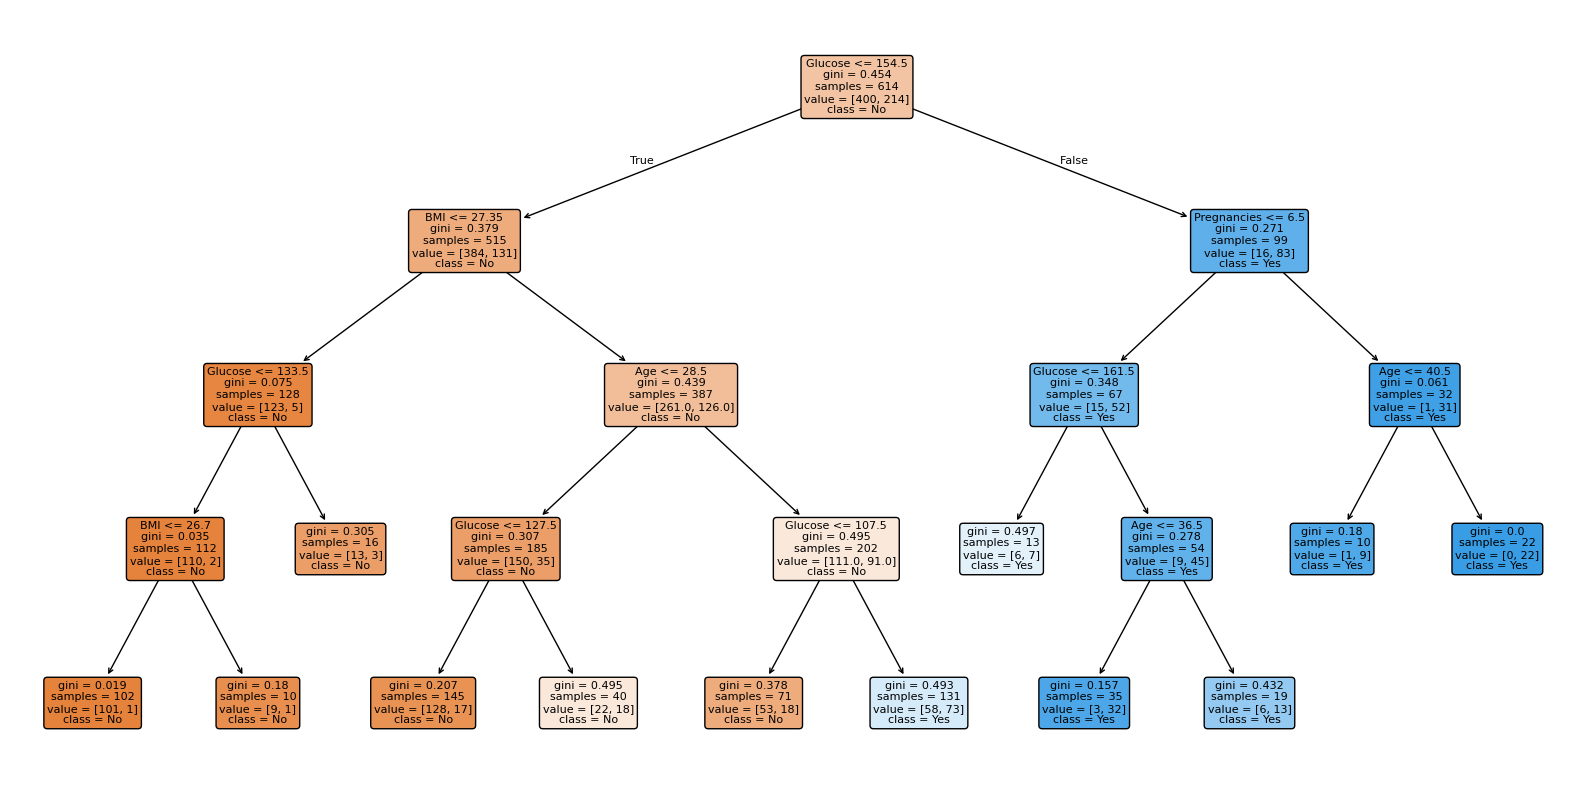

In [ ]:
importance = pd.Series(model.feature_importances_, index=X.columns)
print("Feature importance:\n", importance.sort_values(ascending=False).round(3))


plt.figure(figsize=(16, 8))
plot_tree(model, feature_names=X.columns, class_names=['No', 'Yes'],
          filled=True, rounded=True, fontsize=8)
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=120)
print("\nSaved decision_tree.png")